In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

In [2]:
L = tf.keras.layers

In [3]:
tr = pd.read_csv("fashion-mnist_train.csv")
te = pd.read_csv("fashion-mnist_test.csv")
Xtr,ytr = tr.drop(columns="label").values.reshape(-1,28,28,1) / 255, tr.label.values
Xte,yte = te.drop(columns="label").values.reshape(-1,28,28,1) / 255, te.label.values

In [4]:
model = tf.keras.Sequential([L.Flatten(), L.Dense(256, activation="relu"), L.Dense(128, activation="relu"), L.Dense(10, activation="softmax")])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(optimizer="sgd", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h = model.fit(Xtr, ytr, epochs=11, batch_size=128, validation_data=(Xte, yte))

Epoch 1/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.5622 - loss: 1.4689 - val_accuracy: 0.7612 - val_loss: 0.7165
Epoch 2/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7729 - loss: 0.6745 - val_accuracy: 0.7949 - val_loss: 0.6020
Epoch 3/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8012 - loss: 0.5841 - val_accuracy: 0.8194 - val_loss: 0.5362
Epoch 4/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8219 - loss: 0.5238 - val_accuracy: 0.8263 - val_loss: 0.5036
Epoch 5/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8287 - loss: 0.4947 - val_accuracy: 0.8356 - val_loss: 0.4864
Epoch 6/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8352 - loss: 0.4731 - val_accuracy: 0.8408 - val_loss: 0.4665
Epoch 7/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8370 - loss: 0.4656 - val_accuracy: 0.8398 - val_loss: 0.4627
Epoch 8/11
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8420 - loss: 0.4535 - val_accuracy: 0.

In [6]:
print(model.evaluate(Xte, yte))                                  
print(classification_report(yte, model.predict(Xte).argmax(1)))  

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8494 - loss: 0.4307
[0.4297712445259094, 0.8526999950408936]
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

           0       0.80      0.81      0.81      1000
           1       0.94      0.97      0.96      1000
           2       0.83      0.70      0.76      1000
           3       0.90      0.83      0.86      1000
           4       0.70      0.89      0.79      1000
           5       0.93      0.92      0.92      1000
           6       0.68      0.61      0.64      1000
           7       0.89      0.91      0.90      1000
           8       0.94      0.95      0.94      1000
           9       0.92      0.94      0.93      1000

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.85      0.85      0.85     10000



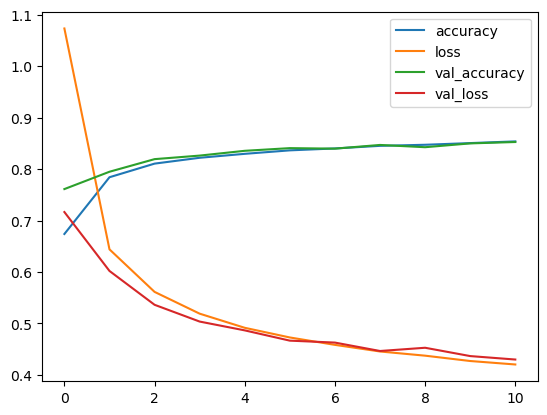

In [7]:
pd.DataFrame(h.history).plot(); 
plt.show()                       

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


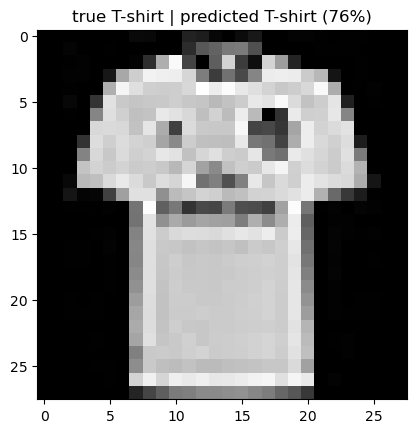

In [8]:
#one example
names = ["T-shirt","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]
i = 0                                                          # any test image
p = model.predict(Xte[i:i+1])[0]                               # one probability per class
plt.imshow(Xte[i].squeeze(), cmap="gray"); plt.title(f"true {names[yte[i]]} | predicted {names[p.argmax()]} ({p.max():.0%})")
plt.show()